# 03 · Data Cleaning

| | |
|---|---|
| **Question** | How do we fix every issue found in the audit without letting future information leak into the model? |
| **Inputs** | `gold.mart_pd_features` (warehouse business rules already applied) |
| **Outputs** | `data/features/pd_<split>.parquet` and the fitted pipeline `models/pd_cleaner.joblib` |
| **Skills shown** | scikit-learn-compatible transformer, fit-on-train discipline, before/after validation, unit tests |

### Where each fix lives

| Fix | Where | Why there |
|---|---|---|
| Household income and DTI for joint applications | Warehouse (`mart_pd_features`) | Deterministic business rule, every consumer needs it |
| Train on 2012+ originations | Loader (`meridian.data.load_pd_split`) | Scope decision for the modelling dataset |
| Winsorisation caps, imputation medians, rare-category lists | `PDCleaner` (`src/meridian/features/cleaning.py`) | Numbers *learned* from data, so fitted on train only |
| Informative-missing flags | `PDCleaner` | Turns "never happened" into an explicit signal |

The cleaner follows the scikit-learn `fit` / `transform` contract, so the exact object fitted here is reused by the scorecard, the challenger model, the monitoring job and the Streamlit app.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from meridian import config, viz
from meridian.data import TARGET, load_pd_split
from meridian.db import connect
from meridian.features.cleaning import (CONTINUOUS, COUNTS, INFORMATIVE_MISSING, RANDOM_MISSING,
                                        FEATURES_CATEGORICAL, FEATURES_NUMERIC, PDCleaner)

viz.set_style()
con = connect()
FEATURES_DIR = config.DATA_DIR / "features"
MODELS_DIR = config.PROJECT_ROOT / "models"
FEATURES_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

## 1. Load the splits

Train is restricted to 2012 to 2014 (the full-bureau era). Validation and test are complete years, so no restriction applies there.

In [2]:
raw = {s: load_pd_split(s, con) for s in ["train", "validation", "test_oot"]}
raw["monitoring"] = load_pd_split("monitoring", con, labelled_only=False)

pd.DataFrame({
    s: {"loans": len(d), "first_issue": d.issue_month.min().strftime("%Y-%m"),
        "last_issue": d.issue_month.max().strftime("%Y-%m"),
        "bad_rate_24m": d[TARGET].astype(float).mean(), "memory_mb": d.memory_usage(deep=True).sum() / 1e6}
    for s, d in raw.items()
}).T.style.format({"loans": "{:,.0f}", "bad_rate_24m": "{:.2%}", "memory_mb": "{:,.0f}"})

,loans,first_issue,last_issue,bad_rate_24m,memory_mb
train,"423,810",2012-01,2014-12,8.96%,84
validation,"421,095",2015-01,2015-12,10.70%,85
test_oot,"434,407",2016-01,2016-12,11.36%,87
monitoring,"938,821",2017-01,2018-12,10.09%,191


The monitoring population (2017 to 2018) has a bad rate only for its Q1 2017 slice. For everything else it is used unlabelled, to detect drift.

## 2. Fit on train, transform everything

In [3]:
cleaner = PDCleaner(lower_q=0.001, upper_q=0.999).fit(raw["train"])
clean = {s: cleaner.transform(d) for s, d in raw.items()}
joblib.dump(cleaner, MODELS_DIR / "pd_cleaner.joblib")

caps = pd.DataFrame({"lower_cap (p0.1)": pd.Series(cleaner.lower_), "upper_cap (p99.9)": pd.Series(cleaner.upper_)})
caps.loc[["annual_income", "debt_to_income", "revolving_balance", "revolving_utilization",
          "loan_to_income", "inquiries_6m", "delinquencies_2y"]].style.format("{:,.3f}")

,lower_cap (p0.1),upper_cap (p99.9)
annual_income,"11,229.472","500,000.000"
debt_to_income,0.004,0.393
revolving_balance,0.000,"235,813.694"
revolving_utilization,0.000,1.021
loan_to_income,0.014,0.500
inquiries_6m,nan,6.000
delinquencies_2y,nan,8.000


**Why fit on train only?** If the caps were computed on all data, the 2016 test borrowers would influence how the 2012 training data is cleaned. The model would then be evaluated on a population it had partly seen, and the reported performance would be optimistic. Here every learned number comes from 2012 to 2014 alone.

## 3. Before and after

In [4]:
def profile(df, cols):
    return pd.DataFrame({"missing": df[cols].isna().mean(), "min": df[cols].min(),
                         "median": df[cols].median(), "max": df[cols].max()})

show = ["annual_income", "debt_to_income", "revolving_utilization", "bankcard_utilization",
        "revolving_balance", "loan_to_income", "employment_years", "months_since_last_delinquency"]
before, after = profile(raw["train"], show), profile(clean["train"], show)
comparison = pd.concat({"before": before, "after": after}, axis=1)
comparison.style.format("{:,.3f}")

- Extreme incomes above USD 1.3M and revolving balances above USD 600K are capped. The medians do not move, which confirms the caps touch only the tails.
- Small random gaps in DTI and utilisation are filled with train medians.
- `employment_years` and the months-since fields deliberately **keep** their missing values. Their meaning is carried by the new flags below and by a dedicated "missing" bin in notebook 05.

In [5]:
flags = ["has_delinquency_history", "has_public_record", "has_recent_inquiry", "employment_not_stated"]
tr = clean["train"]
flag_table = pd.DataFrame({
    "share_of_loans_flagged": tr[flags].mean(),
    "bad_rate_flag_1": [tr.loc[tr[f] == 1, TARGET].astype(float).mean() for f in flags],
    "bad_rate_flag_0": [tr.loc[tr[f] == 0, TARGET].astype(float).mean() for f in flags],
})
flag_table["lift"] = flag_table.bad_rate_flag_1 / flag_table.bad_rate_flag_0
flag_table.style.format({"share_of_loans_flagged": "{:.1%}", "bad_rate_flag_1": "{:.2%}",
                         "bad_rate_flag_0": "{:.2%}", "lift": "{:.2f}x"})

,share_of_loans_flagged,bad_rate_flag_1,bad_rate_flag_0,lift
has_delinquency_history,47.3%,8.93%,8.98%,0.99x
has_public_record,13.9%,9.33%,8.90%,1.05x
has_recent_inquiry,88.3%,9.28%,6.53%,1.42x
employment_not_stated,4.7%,11.73%,8.82%,1.33x


Two flags carry real signal. Borrowers with a credit inquiry in their file default 1.4 times as often as those without one, and borrowers who did not state their employment length default 1.3 times as often. The delinquency and public-record flags are close to neutral on their own; notebook 05 decides whether they earn a place in the model.

`is_joint_application` is also created, but joint applications only started in 2015, so it is constant in the training data. A model cannot learn from a constant. Joint applicants are scored on their household figures instead, which is the more important fix.

## 4. Validate the output

In [6]:
checks = {}
for s, d in clean.items():
    num = d[[c for c in FEATURES_NUMERIC if c not in INFORMATIVE_MISSING and c != "employment_years"]]
    checks[s] = {
        "rows_in": len(raw[s]),
        "rows_out": len(d),
        "unexpected_missing_values": int(num.isna().sum().sum()),
        "values_outside_train_caps": int(sum(((d[c] < cleaner.lower_[c] - 1e-6) | (d[c] > cleaner.upper_[c] + 1e-6)).sum()
                                             for c in CONTINUOUS)),
        "rows_in_OTHER_bucket": int(sum((d[c] == "OTHER").sum() for c in FEATURES_CATEGORICAL)),
    }
pd.DataFrame(checks).T.style.format("{:,.0f}")

,rows_in,rows_out,unexpected_missing_values,values_outside_train_caps,rows_in_OTHER_bucket
train,"423,810","423,810",0,0,"18,306"
validation,"421,095","421,095",0,0,"19,566"
test_oot,"434,407","434,407",0,0,"25,470"
monitoring,"938,821","938,821",0,0,"60,133"


- No rows are lost and no unexpected missing values remain.
- No value falls outside the caps learned on train, including in 2017 and 2018 data.
- Rare categories (small states, uncommon loan purposes, home ownership other than rent, own or mortgage) collapse into `OTHER`. A category that first appears in production will also fall into `OTHER` instead of breaking the model.

The same rules are covered by unit tests in `tests/test_cleaning.py`, which run in CI on every commit.

## 5. A first look at population shift

The cleaner also makes it easy to compare populations on equal terms. How different are the 2016 test borrowers from the 2012 to 2014 training borrowers?

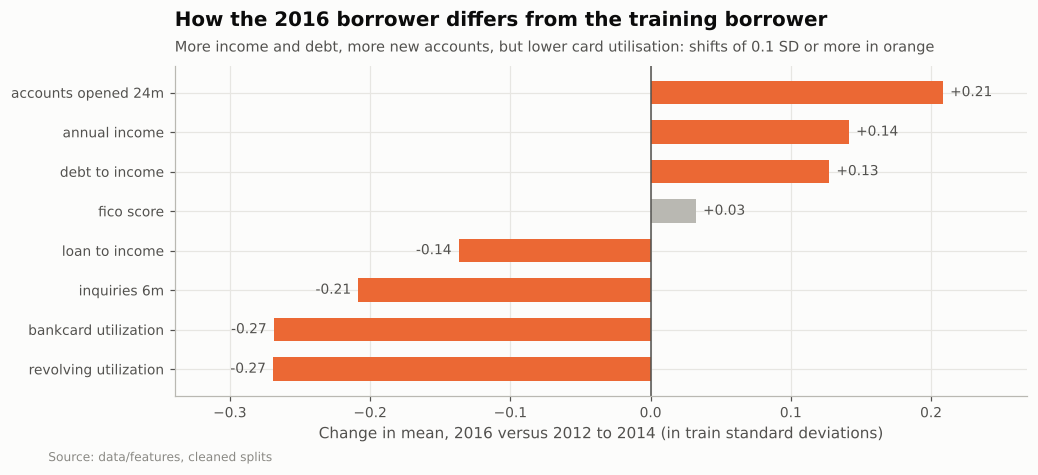

feature,train_median,test_median,standardised_shift
revolving_utilization,0.581,0.504,-0.269
bankcard_utilization,0.704,0.614,-0.269
inquiries_6m,0.000,0.000,-0.209
loan_to_income,0.210,0.192,-0.137
fico_score,692.000,692.000,+0.032
debt_to_income,0.172,0.181,+0.128
annual_income,"63,500.000","68,000.000",+0.142
accounts_opened_24m,4.000,4.000,+0.209


In [7]:
cols = ["fico_score", "debt_to_income", "annual_income", "loan_to_income", "revolving_utilization",
        "accounts_opened_24m", "inquiries_6m", "bankcard_utilization"]
rows = []
for c in cols:
    a, b = clean["train"][c].astype(float), clean["test_oot"][c].astype(float)
    rows.append({"feature": c, "train_median": a.median(), "test_median": b.median(),
                 "standardised_shift": (b.mean() - a.mean()) / a.std()})
shift = pd.DataFrame(rows).sort_values("standardised_shift")

fig, ax = plt.subplots(figsize=(10, 3.9))
colors = [viz.ORANGE if abs(v) >= 0.1 else viz.NEUTRAL for v in shift.standardised_shift]
ax.barh(shift.feature.str.replace("_", " "), shift.standardised_shift, color=colors, height=0.6)
ax.axvline(0, color=viz.INK_2, lw=1)
ax.set_xlim(shift.standardised_shift.min() - 0.07, shift.standardised_shift.max() + 0.06)
for y, v in enumerate(shift.standardised_shift):
    ax.text(v + (0.005 if v >= 0 else -0.005), y, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=viz.INK_2)
ax.grid(axis="x", color=viz.GRID)
ax.set_xlabel("Change in mean, 2016 versus 2012 to 2014 (in train standard deviations)")
ax.set_title("How the 2016 borrower differs from the training borrower")
viz.subtitle(ax, "More income and debt, more new accounts, but lower card utilisation: shifts of 0.1 SD or more in orange")
viz.source(fig, "data/features, cleaned splits")
plt.show()
shift.style.format({"train_median": "{:,.3f}", "test_median": "{:,.3f}", "standardised_shift": "{:+.3f}"}).hide(axis="index")

**What it means:** the 2016 borrower is different in a way that summary risk metrics hide:

- **More leverage:** higher debt-to-income (+0.13 SD) and more accounts opened in the last two years (+0.21 SD).
- **Lower card utilisation and fewer recent inquiries** (about -0.2 to -0.27 SD). This pattern is typical of debt consolidation: borrowers use the loan to pay down cards, which flatters utilisation at the moment of application.
- **FICO is unchanged** (692 median in both periods). A lender watching FICO alone would see no change at all, yet the vintage curves in notebook 01 show these loans default faster.

No single variable moves dramatically, so a well-built model should transfer, but variables such as utilisation may have weaker meaning in 2016. Notebook 12 quantifies this formally with the Population Stability Index.

## 6. Save

In [8]:
for s, d in clean.items():
    d.to_parquet(FEATURES_DIR / f"pd_{s}.parquet", index=False)
pd.DataFrame({s: {"rows": len(d), "columns": d.shape[1],
                  "file_mb": (FEATURES_DIR / f"pd_{s}.parquet").stat().st_size / 1e6}
              for s, d in clean.items()}).T.style.format("{:,.1f}")

,rows,columns,file_mb
train,"423,810.0",56.0,26.5
validation,"421,095.0",56.0,26.8
test_oot,"434,407.0",56.0,27.8
monitoring,"938,821.0",56.0,58.0


## 7. Summary

| Step | Result |
|---|---|
| Training scope | 423,810 loans from 2012 to 2014, consistent bureau inputs |
| Winsorisation | 32 numeric fields capped at train p0.1 / p99.9 |
| Imputation | 21 fields with small random gaps filled with train medians |
| Informative missingness | 4 flags created, each with a clear risk direction |
| Categories | Rare levels grouped into `OTHER`, robust to unseen values |
| Leakage control | Every learned number comes from train only; pipeline saved and reused everywhere |

**Next:** notebook 04 explores what actually drives default in the cleaned training data.